In [58]:
import numpy as np
import matplotlib.pyplot as plt

In [59]:
A2 = 0.5  # коэффициент при u_xx
A = np.sqrt(A2)


def exact(x, t):
    return np.cosh(x - t)


def phi(x):
    return np.cosh(x)


def psi(x):
    return -np.sinh(x)


def f(x, t):
    return 0.5 * np.cosh(x - t)


def g_left(t):
    return np.exp(t)  # u - u_x = g


def g_right(t):
    return 0.5 * (np.exp(1 - t) + 3 * np.exp(t - 1))  # 2u - u_x = g


\begin{align}
    u_0^j - \frac{u_1^j - u_{-1}^j}{2h} &= g_L(t_j) 
    \implies u_{-1}^j = u_1^j - 2h\left(u_0^j - g_L(t_j)\right), \\
    2u_N^j - \frac{u_{N+1}^j - u_{N-1}^j}{2h} &= g_R(t_j) 
    \implies u_{N+1}^j = u_{N-1}^j + 2h\left(2u_N^j - g_R(t_j)\right).
\end{align}

In [66]:
a = np.array([[1,2], [2,2]])
print(a[0])

[1 2]


In [60]:
def solve(h, tau, T, order=2):
    if A * tau / h > 1:
        raise ValueError(f"Курант нарушен: γ={A * tau / h:.3f} > 1")

    x = np.arange(0, 1 + h / 2, h)
    t = np.arange(0, T + tau / 2, tau)
    N, M = len(x) - 1, len(t) - 1
    u = np.zeros((M + 1, N + 1))

    # --- нулевой слой ---
    u[0] = phi(x)

    if order == 1:
        u[1, 1:-1] = u[0, 1:-1] + tau * psi(x[1:-1])
    else:
        lap = (phi(x[2:]) - 2 * phi(x[1:-1]) + phi(x[:-2])) / h**2
        u[1, 1:-1] = (
            u[0, 1:-1]
            + tau * psi(x[1:-1])
            + 0.5 * tau**2 * (A2 * lap + f(x[1:-1], 0))
        )

    # Границы на 1-м слое — правильный расчёт u_xx через фиктивные узлы
    # Левая граница (i=0)
    u_minus_1 = u[0, 1] - 2 * h * (u[0, 0] - g_left(0))
    lap_0 = (u_minus_1 - 2 * u[0, 0] + u[0, 1]) / h**2
    u[1, 0] = (
        u[0, 0] + tau * psi(x[0]) + 0.5 * tau**2 * (A2 * lap_0 + f(x[0], 0))
    )

    # Правая граница (i=N)
    u_plus_1 = u[0, N - 1] + 2 * h * (2 * u[0, N] - g_right(0))
    lap_N = (u_plus_1 - 2 * u[0, N] + u[0, N - 1]) / h**2
    u[1, N] = (
        u[0, N] + tau * psi(x[N]) + 0.5 * tau**2 * (A2 * lap_N + f(x[N], 0))
    )
    # --- основной цикл ---
    g2 = (A * tau / h) ** 2
    for j in range(1, M):
        # внутренние узлы
        u[j + 1, 1:-1] = (
            2 * u[j, 1:-1]
            - u[j - 1, 1:-1]
            + g2 * (u[j, 2:] - 2 * u[j, 1:-1] + u[j, :-2])
            + tau**2 * f(x[1:-1], t[j])
        )

        # левая граница
        um1 = u[j, 1] - 2 * h * (u[j, 0] - g_left(t[j]))
        u[j + 1, 0] = (
            2 * u[j, 0]
            - u[j - 1, 0]
            + g2 * (u[j, 1] - 2 * u[j, 0] + um1)
            + tau**2 * f(x[0], t[j])
        )

        # правая граница
        up1 = u[j, N - 1] + 2 * h * (2 * u[j, N] - g_right(t[j]))
        u[j + 1, N] = (
            2 * u[j, N]
            - u[j - 1, N]
            + g2 * (up1 - 2 * u[j, N] + u[j, N - 1])
            + tau**2 * f(x[N], t[j])
        )

    return x, t, u

In [61]:
def errors(x, t, u):
    U = exact(x[None, :], t[:, None])
    diff = np.abs(u - U)
    return diff.max(), np.sqrt(np.mean(diff**2)), U

In [62]:
def study(h_list, tau_list, T=1.0, order=2):
    res = []
    for h, tau in zip(h_list, tau_list):
        x, t, u = solve(h, tau, T, order)
        eC, eL2, U = errors(x, t, u)
        res.append(dict(h=h, tau=tau, eC=eC, eL2=eL2, x=x, t=t, u=u, U=U))
        print(f"h={h:.4f} τ={tau:.4f} | e_C={eC:.2e} | e_L2={eL2:.2e}")
    return res

Погрешность: ||e||_C = 1.996e-04, ||e||_L2 = 7.814e-05


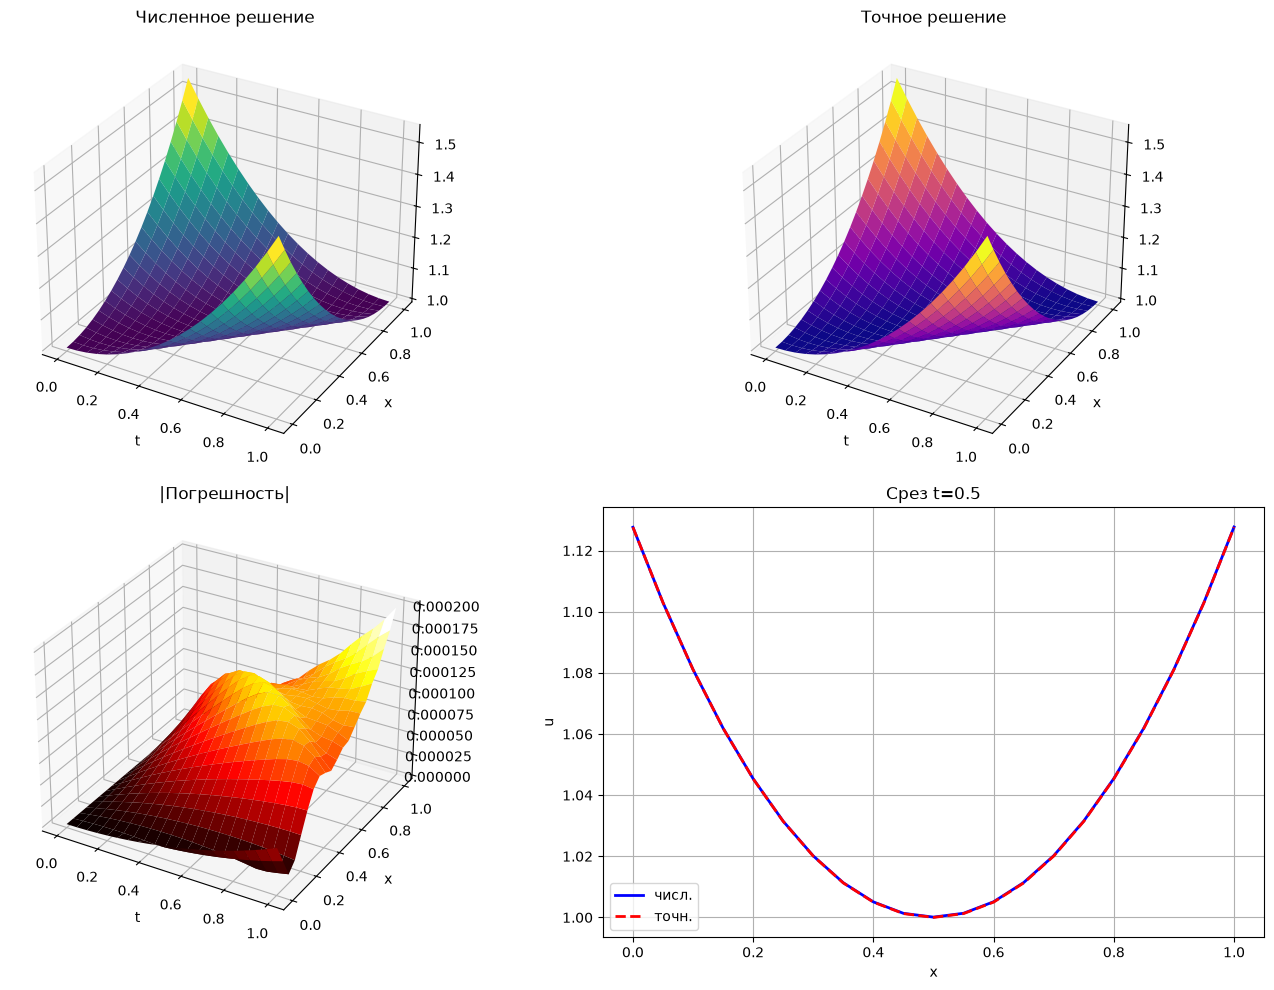

In [63]:
x, t, u = solve(0.05, 0.05, 1.0, order=2)
eC, eL2, U = errors(x, t, u)
print(f"Погрешность: ||e||_C = {eC:.3e}, ||e||_L2 = {eL2:.3e}")

T_mesh, X_mesh = np.meshgrid(t, x, indexing="ij")

fig = plt.figure(figsize=(14, 10))

ax1 = fig.add_subplot(2, 2, 1, projection="3d")
ax1.plot_surface(T_mesh, X_mesh, u, cmap="viridis")
ax1.set_title("Численное решение")
ax1.set_xlabel("t")
ax1.set_ylabel("x")

ax2 = fig.add_subplot(2, 2, 2, projection="3d")
ax2.plot_surface(T_mesh, X_mesh, U, cmap="plasma")
ax2.set_title("Точное решение")
ax2.set_xlabel("t")
ax2.set_ylabel("x")

ax3 = fig.add_subplot(2, 2, 3, projection="3d")
ax3.plot_surface(T_mesh, X_mesh, np.abs(u - U), cmap="hot")
ax3.set_title("|Погрешность|")
ax3.set_xlabel("t")
ax3.set_ylabel("x")

ax4 = fig.add_subplot(2, 2, 4)
k = np.argmin(np.abs(t - 0.5))
ax4.plot(x, u[k], "b-", lw=2, label="числ.")
ax4.plot(x, U[k], "r--", lw=2, label="точн.")
ax4.set_title("Срез t=0.5")
ax4.set_xlabel("x")
ax4.set_ylabel("u")
ax4.legend()
ax4.grid(True)

plt.tight_layout()
plt.show()

h=0.1000 τ=0.1000 | e_C=7.85e-04 | e_L2=3.13e-04
h=0.0500 τ=0.0500 | e_C=2.00e-04 | e_L2=7.81e-05
h=0.0250 τ=0.0250 | e_C=4.99e-05 | e_L2=1.95e-05
h=0.0125 τ=0.0125 | e_C=1.25e-05 | e_L2=4.89e-06
h=0.0063 τ=0.0063 | e_C=3.11e-06 | e_L2=1.22e-06
h=0.1000 τ=0.1000 | e_C=1.17e-01 | e_L2=3.64e-02
h=0.0500 τ=0.0500 | e_C=6.56e-02 | e_L2=1.92e-02
h=0.0250 τ=0.0250 | e_C=3.43e-02 | e_L2=9.84e-03
h=0.0125 τ=0.0125 | e_C=1.75e-02 | e_L2=4.97e-03
h=0.0063 τ=0.0063 | e_C=8.85e-03 | e_L2=2.50e-03
2-й порядок НУ:  p = 1.996
1-й порядок НУ:  p = 0.936


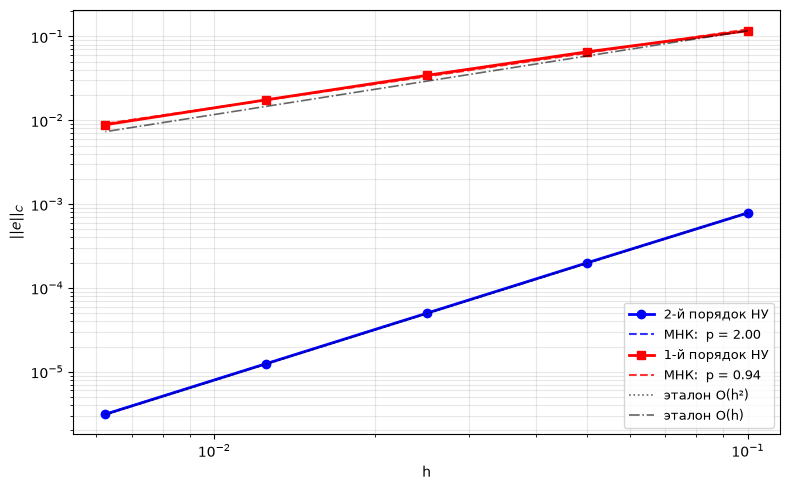

In [64]:
h_vals = [0.1, 0.05, 0.025, 0.0125, 0.00625]
tau_vals = [0.1, 0.05, 0.025, 0.0125, 0.00625]
r2 = study(h_vals, tau_vals, order=2)
r1 = study(h_vals, tau_vals, order=1)

fig, ax = plt.subplots(figsize=(8, 5))

# --- эмпирические данные + МНК-прямые в log-log ---
for r, lbl, c, ce in [
    (r2, "2-й порядок НУ", "bo", "b--"),
    (r1, "1-й порядок НУ", "rs", "r--"),
]:
    hs = np.array([q["h"] for q in r])
    eC = np.array([q["eC"] for q in r])

    # log10(e) = p * log10(h) + b   →   e ≈ C * h^p
    p, b = np.polyfit(np.log10(hs), np.log10(eC), 1)
    print(f"{lbl}:  p = {p:.3f}")

    ax.loglog(hs, eC, c + "-", lw=2, label=lbl)
    ax.loglog(
        hs,
        10 ** (p * np.log10(hs) + b),
        ce,
        lw=1.5,
        alpha=0.8,
        label=f"МНК:  p = {p:.2f}",
    )

# --- теоретические эталоны, привязанные к первой точке ---
hs_all = np.array(h_vals)
eC2_0 = r2[0]["eC"]
eC1_0 = r1[0]["eC"]
ax.loglog(
    hs_all,
    eC2_0 * (hs_all / hs_all[0]) ** 2,
    "k:",
    lw=1.2,
    alpha=0.6,
    label="эталон O(h²)",
)
ax.loglog(
    hs_all,
    eC1_0 * (hs_all / hs_all[0]) ** 1,
    "k-.",
    lw=1.2,
    alpha=0.6,
    label="эталон O(h)",
)

ax.set_xlabel("h")
ax.set_ylabel("$||e||_C$")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()